# Advanced: Visualize the GenAI Use-Case Landscape

**Sub-topic 1.2 — AI Landscape and Industry Use Cases**

This produces a horizontal bar chart — the right chart type here because we're comparing a single **magnitude** (count of use cases) across a categorical axis (industry) with no inherent order. Design choices below follow standard data-viz practice: one hue for a single-series magnitude chart, bars sorted by value (not alphabetically) so the ranking is immediately visible, minimal gridlines, and direct value labels instead of forcing the reader to read off an axis.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("industry_use_cases.csv")
BAR_COLOR = "#2E5EAA"  # single hue -- this is a magnitude chart, not a categorical one

df = pd.read_csv(DATA_PATH)
counts = df.groupby("industry").size().sort_values(ascending=True)  # ascending for horizontal bar order

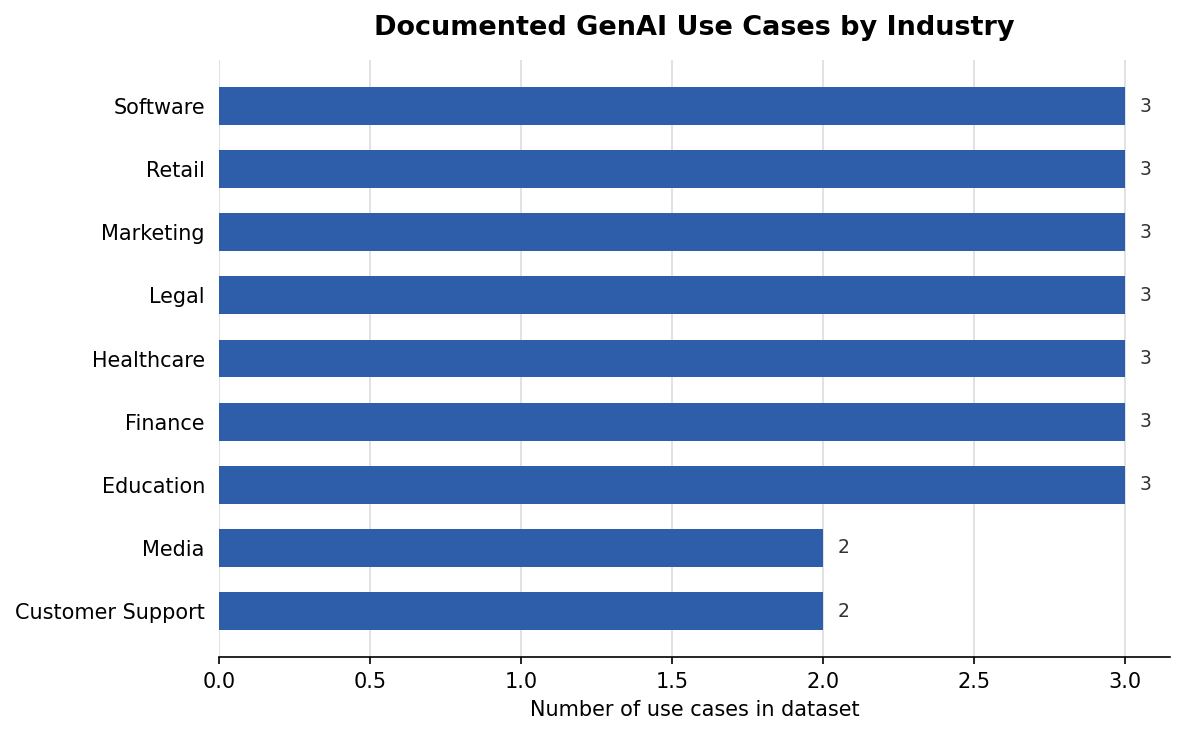

In [2]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

bars = ax.barh(counts.index, counts.values, color=BAR_COLOR, height=0.6)

# Direct value labels at the end of each bar -- avoids forcing the
# reader to trace back to an axis to read exact counts.
for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        ha="left",
        fontsize=9,
        color="#333333",
    )

ax.set_title("Documented GenAI Use Cases by Industry", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Number of use cases in dataset")

# Recessive gridlines/axes: keep only a light x-axis grid, drop the box.
ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)

fig.tight_layout()
plt.show()

### Try it yourself
After adding new rows to `industry_use_cases.csv` (previous notebook's exercise), re-run this notebook and confirm the new industry appears in the chart.